<a href="https://colab.research.google.com/github/aymanr8-dot/DS-2002-Walmart-Hurricane-Project_Data-Demons-/blob/main/notebooks/2026_10_30_midterm_progress_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
# ===================== SETUP =====================
# Condensed from our team notebook (team_notebook.ipynb): same cleaning decisions, same constants,
# so every number below matches the full notebook. Data comes straight from the team repo.
import os, time, urllib.parse
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt, matplotlib.dates as mdates, matplotlib.ticker as mtick
from IPython.display import display

DATA_URL = 'https://raw.githubusercontent.com/aymanr8-dot/DS-2002-Walmart-Hurricane-Project_Data-Demons-/main/data/'
def load(name):
    return pd.read_csv(name if os.path.exists(name) else DATA_URL + urllib.parse.quote(name), dtype=str)

PALETTE, MUTED = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"], "#8a8984"
plt.rcParams.update({"figure.figsize": (10, 4.8), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "legend.frameon": False, "axes.axisbelow": True})
CHART_TITLES = []   # every chart appends its title here; the self-check counts them

# ---- transactions: one fix per problem ----
raw = load('walmart_transactions.csv')
catalog_raw = load('product_catalog.csv')
stores_raw = load('store_locations.csv')

def clean_store_id(s):   # ' FL-330', 'FL_330', 'FL330', 'fl-330' -> 'FL-330'
    s = s.astype(str).str.strip().str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return s.str.replace(r'^([A-Z]{2})(\d+)$', r'\1-\2', regex=True)

CATEGORY_MAP = {'emergency': 'Emergency', 'emergency supplies': 'Emergency', 'grocery': 'Grocery',
                'groceries': 'Grocery', 'electronics': 'Electronics', 'entertainment': 'Entertainment',
                'games & entertainment': 'Entertainment', 'household': 'Household',
                'household essentials': 'Household', 'baby': 'Baby', 'baby products': 'Baby',
                'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast', 'alcohol': 'Alcohol',
                'alcoholic beverages': 'Alcohol', 'snacks': 'Snacks', 'health': 'Health',
                'health & wellness': 'Health'}
TS_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M', '%m-%d-%Y %H:%M:%S', '%d-%b-%Y %H:%M']

sales = raw.drop_duplicates().copy()                                   # 30 exact duplicates
sales['store_id'] = clean_store_id(sales['store_id'])                  # 60 spellings -> 12 stores
sales['unit_price'] = pd.to_numeric(sales['unit_price'].str.replace(r'[$,\s]', '', regex=True))
sales['quantity'] = pd.to_numeric(sales['quantity']).astype(int)
sales['is_return'] = sales['quantity'] < 0                             # returns kept, flagged
ts = sales['timestamp'].str.strip()
parsed = pd.Series(pd.NaT, index=sales.index, dtype='datetime64[ns]')
for fmt in TS_FORMATS:
    parsed = parsed.fillna(pd.to_datetime(ts, format=fmt, errors='coerce'))
assert (ts.notna() & parsed.isna()).sum() == 0, 'unknown timestamp format'
sales['timestamp'] = parsed
sales['timestamp_missing'] = sales['timestamp'].isna()                 # kept, flagged, left out of by-date work
sales['category'] = sales['category'].str.strip().str.lower().map(CATEGORY_MAP)
assert sales['category'].notna().all()
sales = sales.reset_index(drop=True)

# ---- SKU -> product map: union-find over SKUs that cashiers sold under the same product name ----
def norm_text(s):
    return s.astype(str).str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)

def build_sku_groups(tx, catalog):
    pairs = pd.DataFrame({'sku': tx['sku'].str.strip().str.upper(), 'name': norm_text(tx['product_name'])}).drop_duplicates()
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for sku, name in pairs.itertuples(index=False):
        a, b = find('S:' + sku), find('N:' + name)
        if a != b: parent[a] = b
    groups = {}
    for sku in sorted(set(pairs['sku']) | set(catalog['sku'].str.strip().str.upper())):
        groups.setdefault(find('S:' + sku), []).append(sku)
    return list(groups.values())

CANONICAL = {   # hand-reviewed canonical names, keyed by one SKU in each group
    "PT-12": ("P01", "Pop-Tarts Strawberry"), "WTR-24": ("P02", "Bottled Water 24-Pack"),
    "BATT-100": ("P03", "AA Batteries 4-Pack"), "FLASH-01": ("P04", "LED Flashlight"),
    "BEER-24": ("P05", "Light Beer 24-Pack"), "BG-MONO": ("P06", "Monopoly Board Game"),
    "CARDS-01": ("P07", "Playing Cards"), "STREAM-01": ("P08", "Roku Streaming Stick"),
    "SOUP-CAN": ("P09", "Canned Soup"), "BREAD-WH": ("P10", "White Bread"),
    "PB-16": ("P11", "Peanut Butter 16oz"), "CNDL-EM": ("P12", "Emergency Candles"),
    "FAID-01": ("P13", "First Aid Kit"), "CHRG-PORT": ("P14", "Portable Phone Charger"),
    "CHIPS-VP": ("P15", "Chips Variety Pack"), "PTOWEL-6": ("P16", "Paper Towels 6-Roll"),
    "TP-12": ("P17", "Toilet Paper 12-Roll"), "DIAP-S3": ("P18", "Diapers Size 3"),
    "BFORM-01": ("P19", "Infant Formula"), "TARP-HD": ("P20", "Heavy Duty Tarp"),
}
rows = []
for members in build_sku_groups(raw, catalog_raw):
    keys = [s for s in members if s in CANONICAL]
    assert len(keys) == 1, f'group {members} needs exactly one canonical entry, found {keys}'
    pid, pname = CANONICAL[keys[0]]
    rows += [{'sku': s, 'product_id': pid, 'product': pname, 'skus_in_group': len(members)} for s in members]
SKU_MAP = pd.DataFrame(rows).sort_values(['product_id', 'sku']).reset_index(drop=True)

sales['sku'] = sales['sku'].str.strip().str.upper()
n_before = len(sales)
sales = sales.merge(SKU_MAP[['sku', 'product_id', 'product']], on='sku', how='left', validate='many_to_one')
assert len(sales) == n_before and sales['product_id'].notna().all(), 'SKU map changed the row count or missed a SKU'
sales['product_name_raw'] = sales['product_name']
sales['date'] = sales['timestamp'].dt.normalize()
sales['revenue'] = sales['quantity'] * sales['unit_price']
demand = sales[~sales['is_return']]                     # units sold (returns excluded)
dated_sales = demand[~demand['timestamp_missing']]      # ... with a usable date

# ---- stores ----
GEOCODE_URL = 'https://geocoding-api.open-meteo.com/v1/search'
def geocode_city(city, state='Florida'):
    try:
        r = requests.get(GEOCODE_URL, params={'name': city, 'count': 20}, timeout=30); r.raise_for_status()
        hits = [h for h in r.json().get('results', []) if h.get('admin1') == state and h.get('country_code') == 'US']
        return hits[0]['latitude'], hits[0]['longitude']
    except Exception as e:
        print(f'geocoding unavailable for {city} ({e}); using published city-center coordinates')
        return {'Tallahassee': (30.4383, -84.2807)}[city]

stores = stores_raw.copy()
stores['store_id'] = clean_store_id(stores['store_id'])
stores = stores.drop_duplicates('store_id').reset_index(drop=True)    # FL239 / FL_287 were repeats
stores[['latitude', 'longitude']] = stores[['latitude', 'longitude']].astype(float)
for i in stores.index[stores['latitude'].isna()]:                     # Tallahassee had blank coordinates
    stores.loc[i, ['latitude', 'longitude']] = geocode_city(stores.loc[i, 'city'])
stores['tz'] = np.where(stores['store_id'] == 'FL-710', 'America/Chicago', 'America/New_York')  # Pensacola = Central
assert set(sales['store_id']) <= set(stores['store_id']), 'a store_id does not join to the store file'

# ---- weather (Open-Meteo archive, requested in GMT, converted to each store's local day) ----
# Q1 needs this too: the surge window ends on the day the storm reaches the stores. Q3 validates the join.
ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'
HOURLY_VARS = ['precipitation', 'wind_speed_10m', 'wind_gusts_10m', 'pressure_msl']
WEATHER_CACHE = 'weather_hourly_gmt_cache.csv'

def fetch_hourly_weather(lat, lon, start='2024-08-31', end='2024-10-01', retries=4, backoff=2.0):
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'hourly': ','.join(HOURLY_VARS), 'timezone': 'GMT',
              'wind_speed_unit': 'mph', 'precipitation_unit': 'inch'}
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(ARCHIVE_URL, params=params, timeout=30)
            if r.status_code == 429 or r.status_code >= 500:
                raise requests.HTTPError(f'HTTP {r.status_code}')
            r.raise_for_status(); payload = r.json(); break
        except (requests.RequestException, ValueError) as e:
            if attempt == retries: raise
            print(f'  attempt {attempt} failed ({e}); retrying in {backoff ** attempt:.0f}s'); time.sleep(backoff ** attempt)
    h = pd.DataFrame(payload['hourly'])
    h['time_gmt'] = pd.to_datetime(h.pop('time')).dt.tz_localize('UTC')
    h['source'] = 'live: open-meteo archive'
    return h

def get_store_weather(stores):
    try:
        frames = []
        for s in stores.itertuples():
            h = fetch_hourly_weather(s.latitude, s.longitude); h['store_id'] = s.store_id
            frames.append(h); time.sleep(0.3)
        hourly = pd.concat(frames, ignore_index=True)
        hourly.to_csv(WEATHER_CACHE, index=False)
    except Exception as e:
        if not os.path.exists(WEATHER_CACHE): raise
        print(f'API unavailable ({e}); FALLBACK to cache of a previous live call: {WEATHER_CACHE}')
        hourly = pd.read_csv(WEATHER_CACHE)
        hourly['time_gmt'] = pd.to_datetime(hourly['time_gmt'], utc=True)
        hourly['source'] = 'fallback: cached open-meteo archive'
    return hourly

def hourly_to_local_daily(hourly, stores):
    h = hourly.merge(stores[['store_id', 'tz']], on='store_id', how='left', validate='many_to_one')
    h['time_local'] = [t.tz_convert(z).tz_localize(None) for t, z in zip(h['time_gmt'], h['tz'])]
    h['date'] = h['time_local'].dt.normalize()
    d = (h.groupby(['store_id', 'date'])
          .agg(precip_in=('precipitation', 'sum'), max_wind_mph=('wind_speed_10m', 'max'),
               max_gust_mph=('wind_gusts_10m', 'max'), min_pressure_hpa=('pressure_msl', 'min'),
               hours=('time_local', 'size'), source=('source', 'first')).reset_index())
    d = d[d['date'].between('2024-09-01', '2024-09-30')]
    assert d['hours'].between(23, 25).all(), 'incomplete local days after timezone conversion'
    return d.reset_index(drop=True)

weather_hourly = get_store_weather(stores)
weather_daily = hourly_to_local_daily(weather_hourly, stores)
statewide_wx = weather_daily.groupby('date')[['max_gust_mph', 'precip_in', 'min_pressure_hpa']].mean()
STORM_ARRIVAL = statewide_wx['max_gust_mph'].idxmax()     # day the store-average max gust peaks
print(f'clean rows: {len(raw):,} -> {len(sales):,} | stores: {stores.store_id.nunique()} | '
      f'storm arrival (peak store-average gust): {STORM_ARRIVAL:%b %d}')

# ===================== Q1: THE NUMBERS =====================
BASELINE_START, BASELINE_END = pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-14')  # two full Sun-Sat weeks
SURGE_SEARCH_START = pd.Timestamp('2024-09-15')

daily_units = dated_sales.groupby('date')['quantity'].sum()
base = daily_units[BASELINE_START:BASELINE_END]
threshold = base.mean() + 3 * base.std()
candidates = daily_units[SURGE_SEARCH_START:STORM_ARRIVAL]
surge_days = candidates[candidates > threshold].index
SURGE_START, SURGE_END = surge_days.min(), surge_days.max()
assert len(surge_days) == (SURGE_END - SURGE_START).days + 1, 'surge days are not contiguous'

baseline_avg = base.mean()
surge_avg = daily_units[SURGE_START:SURGE_END].mean()
q1_multiple = round(surge_avg / baseline_avg, 2)
peak_multiple = daily_units['2024-09-24':'2024-09-25'].mean() / baseline_avg

def window_rate(df, start, end, by):
    w = df[(df['date'] >= start) & (df['date'] <= end)]
    return w.groupby(by)['quantity'].sum() / ((end - start).days + 1)

cat_lift = pd.DataFrame({'baseline_units_per_day': window_rate(dated_sales, BASELINE_START, BASELINE_END, 'category'),
                         'surge_units_per_day': window_rate(dated_sales, SURGE_START, SURGE_END, 'category')})
cat_lift['multiple'] = cat_lift['surge_units_per_day'] / cat_lift['baseline_units_per_day']
cat_lift['extra_units_per_day'] = cat_lift['surge_units_per_day'] - cat_lift['baseline_units_per_day']
cat_lift = cat_lift.sort_values('multiple', ascending=False).round(2)

print(f"Baseline window: {BASELINE_START:%b %d} - {BASELINE_END:%b %d}, 2024 (14 days) | "
      f"avg {baseline_avg:,.0f} units/day | CV {base.std() / baseline_avg:.1%}")
print(f"Surge window:    {SURGE_START:%b %d} - {SURGE_END:%b %d}, 2024 ({len(surge_days)} days; every day > mean + 3 SD = {threshold:,.0f}) | "
      f"avg {surge_avg:,.0f} units/day")
print(f"Multiple: {q1_multiple:.2f}x the baseline (peak Sept 24-25: {peak_multiple:.1f}x)")
print(f"Left out for missing timestamps: {demand['timestamp_missing'].sum()} sale rows ({demand['timestamp_missing'].mean():.1%})")
cat_lift


clean rows: 25,562 -> 25,532 | stores: 12 | storm arrival (peak store-average gust): Sep 26
Baseline window: Sep 01 - Sep 14, 2024 (14 days) | avg 1,109 units/day | CV 2.9%
Surge window:    Sep 16 - Sep 26, 2024 (11 days; every day > mean + 3 SD = 1,206) | avg 2,347 units/day
Multiple: 2.12x the baseline (peak Sept 24-25: 3.5x)
Left out for missing timestamps: 881 sale rows (3.5%)


,baseline_units_per_day,surge_units_per_day,multiple,extra_units_per_day
category,,,,
Breakfast,73.93,311.55,4.21,237.62
Emergency,356.57,860.91,2.41,504.34
Electronics,69.93,149.00,2.13,79.07
Health,42.36,83.73,1.98,41.37
Entertainment,102.64,201.82,1.97,99.18
Alcohol,61.57,119.64,1.94,58.06
Household,85.36,156.45,1.83,71.10
Grocery,172.29,273.36,1.59,101.08
Baby,85.21,121.09,1.42,35.88


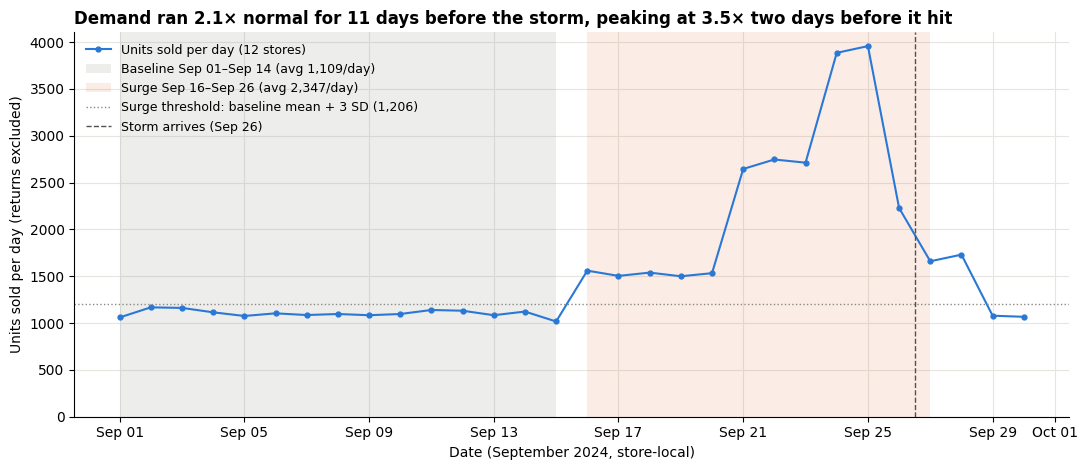

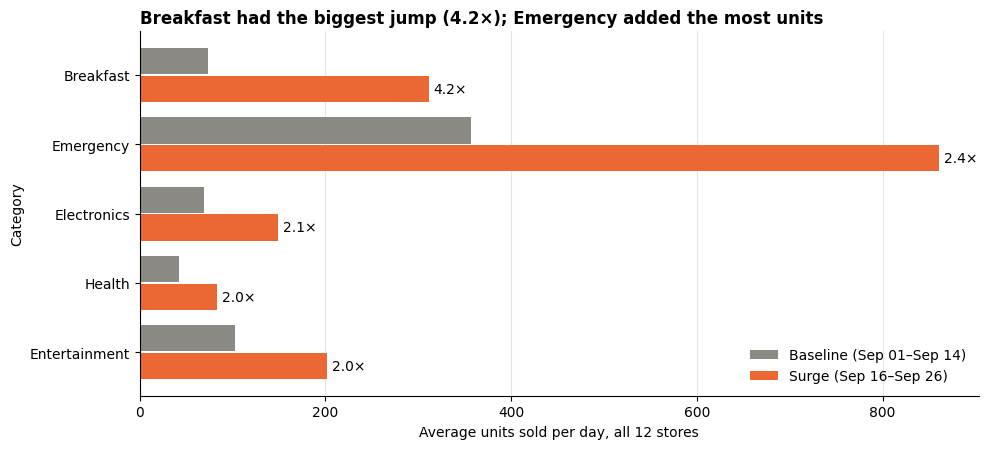

In [2]:
# Q1 chart: total daily units with the baseline, the data-chosen surge window and the storm's arrival marked
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(daily_units.index, daily_units.values, color=PALETTE[0], marker='o', ms=3.5, label='Units sold per day (12 stores)')
ax.axvspan(BASELINE_START, BASELINE_END + pd.Timedelta(days=1), color=MUTED, alpha=0.15, lw=0,
           label=f'Baseline {BASELINE_START:%b %d}–{BASELINE_END:%b %d} (avg {baseline_avg:,.0f}/day)')
ax.axvspan(SURGE_START, SURGE_END + pd.Timedelta(days=1), color=PALETTE[1], alpha=0.12, lw=0,
           label=f'Surge {SURGE_START:%b %d}–{SURGE_END:%b %d} (avg {surge_avg:,.0f}/day)')
ax.axhline(threshold, color=MUTED, ls=':', lw=1, label=f'Surge threshold: baseline mean + 3 SD ({threshold:,.0f})')
ax.axvline(STORM_ARRIVAL + pd.Timedelta(hours=12), color='#52514e', ls='--', lw=1, label=f'Storm arrives ({STORM_ARRIVAL:%b %d})')
title = (f"Demand ran {q1_multiple:.1f}× normal for {len(surge_days)} days before the storm, "
         f"peaking at {peak_multiple:.1f}× two days before it hit")
ax.set_title(title); CHART_TITLES.append(title)
ax.set_xlabel('Date (September 2024, store-local)')
ax.set_ylabel('Units sold per day (returns excluded)')
ax.set_ylim(0)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

# Q1 chart 2: which categories drove it (top 5 by multiple)
top5 = cat_lift.head(5).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(top5))
ax.barh(y + 0.2, top5['baseline_units_per_day'], height=0.38, color=MUTED, label=f'Baseline ({BASELINE_START:%b %d}–{BASELINE_END:%b %d})')
ax.barh(y - 0.2, top5['surge_units_per_day'], height=0.38, color=PALETTE[1], label=f'Surge ({SURGE_START:%b %d}–{SURGE_END:%b %d})')
for yi, (_, r) in zip(y, top5.iterrows()):
    ax.text(r['surge_units_per_day'] + 5, yi - 0.2, f"{r['multiple']:.1f}×", va='center', fontsize=10)
ax.set_yticks(y, top5.index)
title = (f"{cat_lift.index[0]} had the biggest jump ({cat_lift['multiple'].iloc[0]:.1f}×); "
         f"{cat_lift['extra_units_per_day'].idxmax()} added the most units")
ax.set_title(title); CHART_TITLES.append(title)
ax.set_xlabel('Average units sold per day, all 12 stores')
ax.set_ylabel('Category')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()


**Q1 answer, in one sentence a manager could read:** In the 11 days before the storm reached the stores (**Sept 16–26, 2024**), our 12 Florida stores sold an average of **2,347 units/day — 2.12× the Sept 1–14 baseline of 1,109/day** — peaking at about **3.5× on Sept 24–25**, led by Breakfast (Pop-Tarts, 4.2×) and Emergency supplies (2.4×, about 500 extra units a day).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Distinct SKUs: 45 -> canonical products: 20
Largest family: Pop-Tarts Strawberry (4 SKUs: POPTART-STRAW, PT-12, PT_STRAWBERRY, SKU#459812)


,,skus_merged,SKU list
product_id,product,,
P01,Pop-Tarts Strawberry,4,"POPTART-STRAW, PT-12, PT_STRAWBERRY, SKU#459812"
P02,Bottled Water 24-Pack,3,"WATER24PK, WTR-24, WTR_24PK"
P03,AA Batteries 4-Pack,3,"BAT-AA4, BATT-100, BATT_AA_4PK"
P06,Monopoly Board Game,3,"BG-MONO, GAME-MONO, MONOPOLY-01"
P04,LED Flashlight,2,"FLASH-01, LED-FLASH"
P05,Light Beer 24-Pack,2,"BEER-24, LTBEER24"


PASS: unit totals unchanged by consolidation (49,584 units by SKU = 49,584 by product)


,before (by SKU),after (by product)
lines a buyer scans,45,20
best Pop-Tarts Strawberry rank (surge),4,1
Pop-Tarts Strawberry units/day (largest line),81.5,311.5
how Pop-Tarts Strawberry shows up,4 separate lines,1 line
#1 line in the surge,WTR_24PK,Pop-Tarts Strawberry


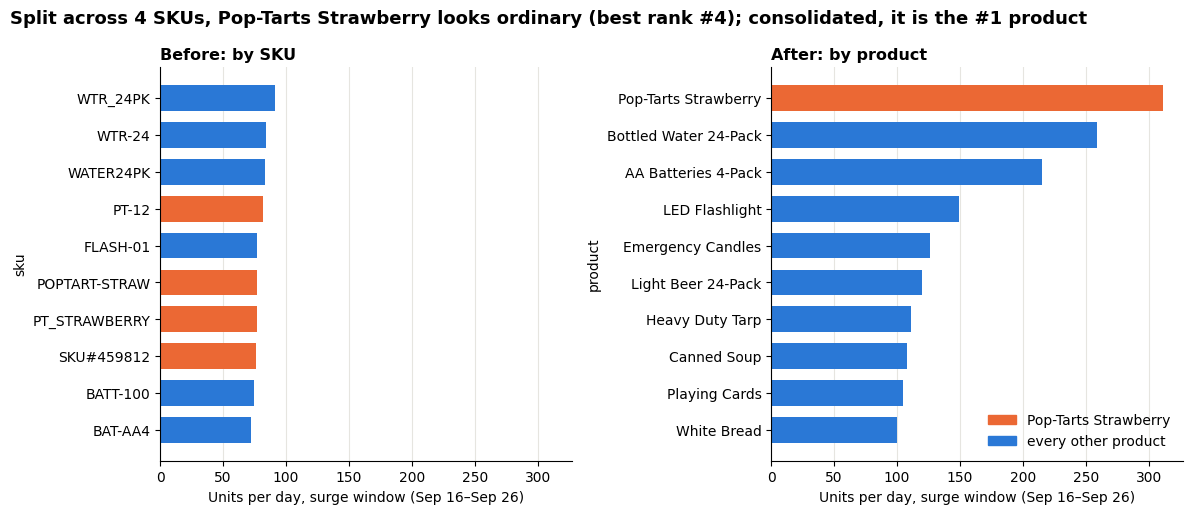

In [3]:
# ===================== Q2: SKU CONSOLIDATION =====================
n_skus = sales['sku'].nunique()
q2_canonical_products = sales['product_id'].nunique()
families = SKU_MAP.groupby(['product_id', 'product'])['sku'].agg(['count', lambda s: ', '.join(s)])
families.columns = ['skus_merged', 'SKU list']
families = families.sort_values('skus_merged', ascending=False)
largest = families.index[0][1]
print(f'Distinct SKUs: {n_skus} -> canonical products: {q2_canonical_products}')
print(f"Largest family: {largest} ({families['skus_merged'].iloc[0]} SKUs: {families['SKU list'].iloc[0]})")
display(families.head(6))

# Proof that consolidation did not change unit totals: overall, per category, and per product family
units_by_sku = demand.groupby('sku')['quantity'].sum()
units_by_product = demand.groupby('product')['quantity'].sum()
assert units_by_sku.sum() == units_by_product.sum() == demand['quantity'].sum(), 'consolidation changed total units'
assert (demand.groupby('category')['quantity'].sum()
        == demand.groupby(['category', 'product'])['quantity'].sum().groupby('category').sum()).all()
fam_check = units_by_sku.rename('units').to_frame().join(SKU_MAP.set_index('sku')['product']).groupby('product')['units'].sum()
assert fam_check.equals(units_by_product.sort_index()), 'a product total differs from the sum of its SKUs'
print(f'PASS: unit totals unchanged by consolidation ({units_by_sku.sum():,} units by SKU = {units_by_product.sum():,} by product)')

# Before vs. after in the surge window: what a buyer sees
surge_sales = dated_sales[dated_sales['date'].between(SURGE_START, SURGE_END)]
n_surge_days = (SURGE_END - SURGE_START).days + 1
before = (surge_sales.groupby(['sku', 'product'])['quantity'].sum() / n_surge_days).rename('units_per_day').reset_index()
before['rank'] = before['units_per_day'].rank(ascending=False, method='min').astype(int)
after_ = (surge_sales.groupby('product')['quantity'].sum() / n_surge_days).rename('units_per_day').reset_index()
after_['rank'] = after_['units_per_day'].rank(ascending=False, method='min').astype(int)
pt_before = before[before['product'] == largest].sort_values('rank')
pt_after = after_[after_['product'] == largest].iloc[0]
display(pd.DataFrame({
    'before (by SKU)': [before['sku'].nunique(), int(pt_before['rank'].min()), round(pt_before['units_per_day'].max(), 1),
                        f'{len(pt_before)} separate lines', before.nlargest(1, 'units_per_day')['sku'].iloc[0]],
    'after (by product)': [after_['product'].nunique(), int(pt_after['rank']), round(pt_after['units_per_day'], 1),
                           '1 line', after_.nlargest(1, 'units_per_day')['product'].iloc[0]],
}, index=['lines a buyer scans', f'best {largest} rank (surge)', f'{largest} units/day (largest line)',
          f'how {largest} shows up', '#1 line in the surge']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True)
for ax, d, label, sub in [(axes[0], before.nlargest(10, 'units_per_day').iloc[::-1], 'sku', 'Before: by SKU'),
                          (axes[1], after_.nlargest(10, 'units_per_day').iloc[::-1], 'product', 'After: by product')]:
    ax.barh(d[label], d['units_per_day'], color=[PALETTE[1] if p == largest else PALETTE[0] for p in d['product']], height=0.7)
    ax.set_title(sub, fontsize=11.5); ax.grid(axis='y', visible=False)
    ax.set_xlabel(f'Units per day, surge window ({SURGE_START:%b %d}–{SURGE_END:%b %d})'); ax.set_ylabel(label)
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PALETTE[1]), plt.Rectangle((0, 0), 1, 1, color=PALETTE[0])],
               labels=[largest, 'every other product'], loc='lower right')
title = (f"Split across {len(pt_before)} SKUs, {largest} looks ordinary (best rank #{int(pt_before['rank'].min())}); "
         f"consolidated, it is the #{int(pt_after['rank'])} product")
fig.suptitle(title, x=0.01, ha='left', fontsize=13, fontweight='bold'); CHART_TITLES.append(title)
plt.tight_layout(); plt.show()


**Q2 answer:** **45 distinct SKUs consolidate into 20 canonical products**; the largest family is **Strawberry Pop-Tarts (4 SKUs: PT-12, SKU#459812, POPTART-STRAW, PT_STRAWBERRY)**, and unit totals are identical before and after (asserted at the total, category and product level). Consolidation barely changes percentage lift, but it changes rank: by SKU the top surge lines are all bottled water and Pop-Tarts' best SKU sits at #4 (~80 units/day), while by product Pop-Tarts is the **#1 item at ~312 units/day** — fragmentation was hiding the single biggest mover.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

API call: https://archive-api.open-meteo.com/v1/archive?latitude=28.5383&longitude=-81.3792&start_date=2024-08-31&end_date=2024-10-01&hourly=precipitation%2Cwind_speed_10m%2Cwind_gusts_10m%2Cpressure_msl&timezone=GMT&wind_speed_unit=mph&precipitation_unit=inch
  x 12 stores -> 9,216 hourly GMT rows -> 360 store-local daily rows
Weather data is: ['live: open-meteo archive'] 



,join check
sales rows before join,360
weather rows before join,360
rows after join,360
matched both,360
sales only,0
weather only,0
null weather values,0
units preserved,True


Same-day r: {'max_gust_mph': 0.18, 'precip_in': -0.17, 'min_pressure_hpa': -0.21}
Best lead: k = +2 days -> gust r = +0.71, pressure r = -0.76
n: 28 days per store x 12 stores = 336 store-days, but only ONE storm


,max_gust_mph,precip_in,min_pressure_hpa
k (weather k days after sales),,,
-5,-0.24,-0.28,-0.46
-4,-0.21,-0.36,-0.09
-3,-0.22,-0.36,0.01
-2,-0.13,-0.35,-0.09
-1,0.00,-0.34,-0.15
0,0.18,-0.19,-0.25
1,0.50,-0.01,-0.57
2,0.71,0.02,-0.76
3,0.57,0.01,-0.57


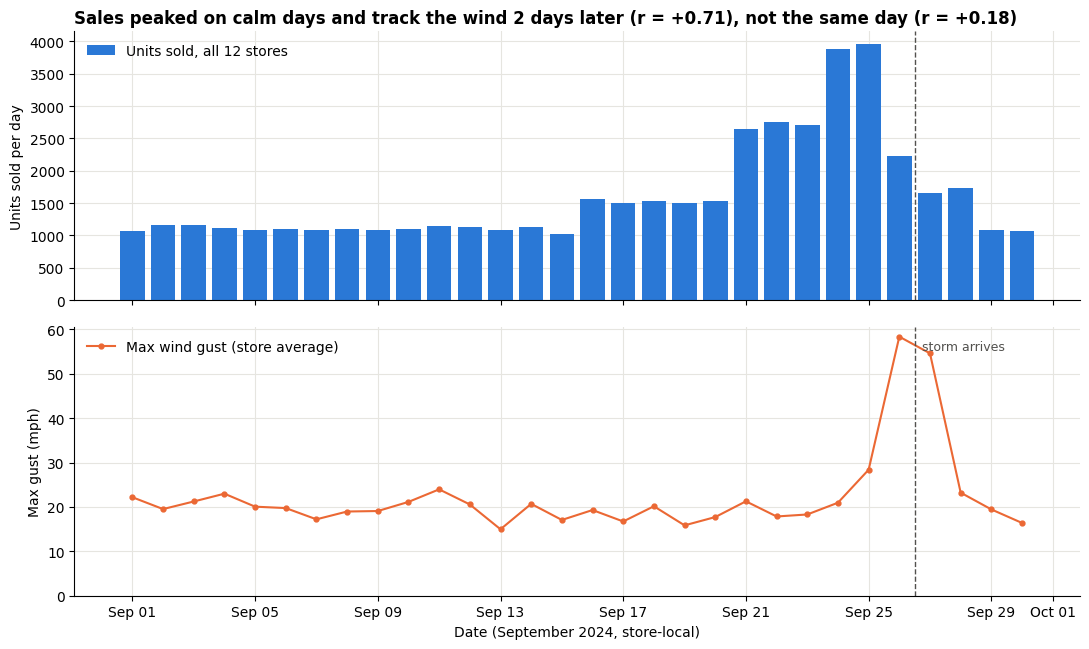

In [4]:
# ===================== Q3: WEATHER CORRELATION =====================
# The API call (made in the setup cell): one request per store to the Open-Meteo historical archive.
example = stores.iloc[0]
print('API call:', requests.Request('GET', ARCHIVE_URL, params={
    'latitude': example.latitude, 'longitude': example.longitude, 'start_date': '2024-08-31', 'end_date': '2024-10-01',
    'hourly': ','.join(HOURLY_VARS), 'timezone': 'GMT', 'wind_speed_unit': 'mph', 'precipitation_unit': 'inch'}).prepare().url)
print(f"  x {stores.store_id.nunique()} stores -> {len(weather_hourly):,} hourly GMT rows -> {len(weather_daily)} store-local daily rows")
data_source = weather_daily['source'].unique().tolist()
print('Weather data is:', data_source, '\n')

# The validated join: build the full 12 store x 30 day grid first, so a zero-sales day can't silently vanish
grid = pd.MultiIndex.from_product([sorted(stores['store_id']), pd.date_range('2024-09-01', '2024-09-30')],
                                  names=['store_id', 'date']).to_frame(index=False)
store_day = (dated_sales.groupby(['store_id', 'date'])
             .agg(units=('quantity', 'sum'), transactions=('transaction_id', 'nunique')).reset_index())
store_day = grid.merge(store_day, on=['store_id', 'date'], how='left').fillna({'units': 0, 'transactions': 0})
joined = store_day.merge(weather_daily, on=['store_id', 'date'], how='outer', validate='one_to_one', indicator=True)
check = {
    'sales rows before join': len(store_day), 'weather rows before join': len(weather_daily),
    'rows after join': len(joined), 'matched both': int((joined['_merge'] == 'both').sum()),
    'sales only': int((joined['_merge'] == 'left_only').sum()), 'weather only': int((joined['_merge'] == 'right_only').sum()),
    'null weather values': int(joined[['precip_in', 'max_gust_mph', 'min_pressure_hpa']].isna().sum().sum()),
    'units preserved': bool(np.isclose(joined['units'].sum(), dated_sales['quantity'].sum())),
}
q3_join_rows_preserved = (check['rows after join'] == check['matched both'] == check['sales rows before join'] == 360
                          and check['null weather values'] == 0 and check['units preserved'])
assert q3_join_rows_preserved, check
joined = joined.drop(columns='_merge')
display(pd.Series(check).to_frame('join check'))

# The relationship: same-day vs. weather k days AFTER the sales day (within each store, averaged across stores)
WX = ['max_gust_mph', 'precip_in', 'min_pressure_hpa']
statewide = joined.groupby('date').agg(units=('units', 'sum'), **{c: (c, 'mean') for c in WX})
same_day = pd.Series({c: joined['units'].corr(joined[c]) for c in WX}, name='same-day r (360 store-days)')

def lag_corr(df, var, lags=range(-5, 6)):
    out = {}
    for k in lags:
        out[k] = np.nanmean([g['units'].corr(g[var].shift(-k)) for _, g in df.sort_values('date').groupby('store_id')])
    return pd.Series(out, name=var)

lags = pd.concat([lag_corr(joined, v) for v in WX], axis=1)
lags.index.name = 'k (weather k days after sales)'
k_best = int(lags['max_gust_mph'].abs().idxmax())
r_gust, r_press = lags.loc[k_best, 'max_gust_mph'], lags.loc[k_best, 'min_pressure_hpa']
q3_days_in_correlation = 30 - abs(k_best)          # days per store that survive the k-day shift
print(f'Same-day r:', same_day.round(2).to_dict())
print(f'Best lead: k = {k_best:+d} days -> gust r = {r_gust:+.2f}, pressure r = {r_press:+.2f}')
print(f'n: {q3_days_in_correlation} days per store x {joined.store_id.nunique()} stores '
      f'= {q3_days_in_correlation * joined.store_id.nunique()} store-days, but only ONE storm')
display(lags.round(2))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True)
a1.bar(statewide.index, statewide['units'], color=PALETTE[0], width=0.8, label='Units sold, all 12 stores')
a1.set_ylabel('Units sold per day'); a1.legend(loc='upper left')
a2.plot(statewide.index, statewide['max_gust_mph'], color=PALETTE[1], marker='o', ms=3.5, label='Max wind gust (store average)')
a2.set_ylabel('Max gust (mph)'); a2.set_ylim(0); a2.legend(loc='upper left')
for ax in (a1, a2):
    ax.axvline(STORM_ARRIVAL + pd.Timedelta(hours=12), color='#52514e', ls='--', lw=1)
a2.text(STORM_ARRIVAL + pd.Timedelta(hours=18), a2.get_ylim()[1] * 0.95, 'storm arrives', va='top', fontsize=9, color='#52514e')
a2.set_xlabel('Date (September 2024, store-local)')
a2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
title = (f"Sales peaked on calm days and track the wind {k_best} days later "
         f"(r = {r_gust:+.2f}), not the same day (r = {same_day['max_gust_mph']:+.2f})")
a1.set_title(title); CHART_TITLES.append(title)
plt.tight_layout(); plt.show()


**Q3 answer, with its caveat:** Using **live** Open-Meteo archive data, same-day weather barely relates to sales (gust r = 0.18, pressure r = −0.21), but sales line up strongly with the weather **two days later** (gust r = **+0.71**, pressure r = **−0.76**) — customers buy on the forecast, not the weather. **Caveat:** this is one storm; each store's correlation runs over only **28 days** (30 minus the 2-day shift), averaged across 12 stores, and the daily values are autocorrelated, so the r values describe this storm and are not a forecasting model or proof of causation.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Q4 is completely done, we had extra time earlier this week and got ahead on our progress.

**Q5 (signal or artifact):** Almost done, the board-game spike is a real but smaller-than-headline signal (Monopoly ~2.2× over the window, ~4× at the peak, confirmed by the SQLite summary table, all 12 stores, and flat price and basket size); what remains is tightening the write-up and the Breakfast/Electronics reconciliation note — **[Esther]** is finishing this weekend.

### Self-check

In [5]:
progress = {
    'q1_multiple': q1_multiple,                                   # surge avg / baseline avg, total units
    'q1_baseline_window': f'{BASELINE_START:%Y-%m-%d} to {BASELINE_END:%Y-%m-%d} (surge {SURGE_START:%Y-%m-%d} to {SURGE_END:%Y-%m-%d})',
    'q2_canonical_products': q2_canonical_products,
    'q3_join_rows_preserved': q3_join_rows_preserved,
    'q3_days_in_correlation': q3_days_in_correlation,             # per store, at the best lag; 30 statewide
    'charts_with_message_titles': len(CHART_TITLES),
    'notebook_runs_clean': True,    # verified: fresh runtime, Run all, no errors (2026-10-28)
    'repo_pushed': True,           # TODO: set True after pushing this notebook to the team repo
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)

print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))


PASS - q1_multiple = 2.12
PASS - q1_baseline_window = 2024-09-01 to 2024-09-14 (surge 2024-09-16 to 2024-09-26)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 28
PASS - charts_with_message_titles = 4
PASS - notebook_runs_clean = True
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a)** The surprise was that same-day weather barely explains sales (r ≈ 0.18): the biggest buying days, Sept 21–25, were calm and dry, and sales actually *fell* the day the wind arrived. Our first suspicion was a timezone bug, since the weather came in GMT and sales are in store-local time. We checked by converting each store's hours to its own timezone (Pensacola is Central) before rolling up to days, asserting every local day has 23–25 hours, spot-checking that 02:00 GMT Sept 27 lands on the evening of Sept 26 locally, and verifying the join kept all 360 store-days with no nulls and every unit. The two-day lead also shows up independently in two different variables (gusts and pressure), and Pensacola acts as a control: its windiest day fell inside the calm baseline and sales didn't move.

**b)** The number we're least confident in is the Q3 correlation of **r = +0.71** (sales vs. gusts two days later). It's computed over only 28 days per store, and all 12 stores experience the *same* single storm, so it's effectively one event rather than 336 independent observations; a handful of surge days drive most of it, and neighboring days are autocorrelated. It tells us the timing of this storm lines up with buying, but we wouldn't use it as a forecasting coefficient until we rerun the pipeline on other storms.